# Avance 1 — Análisis exploratorio (EDA)
**Proyecto Integrador DATA STARTUP · MineTrac · Cliente: Máquinas Centella S.A. de C.V.**
Carlos Vázquez · Diego Reyes Natilla · TecNM Colima, Ingeniería en Inteligencia Artificial · Noviembre de 2026

## 1. Definición del problema
**Pregunta de negocio.** Cuando un equipo de Máquinas Centella entra a taller por una falla en un sistema (motor, tren motriz y frenos, eléctrico/A-C, estructura, llantas), ¿volverá a registrar una falla en *ese mismo sistema* en los siguientes 30 días?

**Variable objetivo:** `repite_30d` (binaria, **clasificación**). Vale 1 si el mismo equipo registra otra intervención en el mismo sistema entre 1 y 30 días después; 0 si no. Se construye solo mirando hacia adelante en el tiempo, y queda vacía (no se usa) para servicios preventivos, registros sin clasificar, registros sin fecha y los últimos 30 días de datos (aún no se puede saber).

**Justificación y valor práctico.** La empresa lleva su mantenimiento a mano y reacciona a cada falla. Una falla que se repite en un mes suele indicar una reparación incompleta o una pieza que sigue en riesgo. Anticiparla permite: (a) apartar la refacción antes de que el equipo vuelva a parar, (b) priorizar revisión de seguimiento en el taller y (c) reducir horas de máquina detenida. Las variables explicativas son solo información disponible *antes* del momento de decisión (historial previo del equipo, sistema, tipo de equipo, mes), por lo que el modelo sería utilizable en la práctica.

In [1]:
import sys, warnings; warnings.filterwarnings('ignore')
sys.path.insert(0, '../services/worker')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from dataset_riesgo import construir_dataset
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.25})
AZ,NA,GR='#1f4e79','#d9822b','#7f7f7f'
mant = pd.read_csv('../data/clean/mantenimiento.csv')
lib  = pd.read_csv('../data/clean/libreta_eventos.csv')
df = construir_dataset(mant, lib)
df.to_csv('../data/clean/dataset_avance1.csv', index=False)
print(df.shape)
df.head()

(857, 18)


,fuente,equipo_id,tipo_equipo,fecha,fecha_calidad,sistema_original,monto_mxn,pieza_declarada,proveedor_declarado,es_servicio,intervalo_servicio_h,sistema,mes,dia_semana,dias_desde_previo_equipo,registros_previos_90d,previos_mismo_sistema_90d,repite_30d
0,bitacora_camiones,C1,Camión,2023-08-04,ok,"Caja, frenos y suspensión neumática",NaN,0,0,0,NaN,tren_motriz_frenos,8.0,4.0,NaN,0.0,0.0,0.0
1,bitacora_camiones,C1,Camión,2024-04-15,ok,Estético y cabina,NaN,0,0,0,NaN,estructura_cabina,4.0,0.0,255.0,0.0,0.0,1.0
2,bitacora_camiones,C1,Camión,2024-05-15,ok,Estético y cabina,NaN,0,0,0,NaN,estructura_cabina,5.0,2.0,30.0,1.0,1.0,0.0
3,bitacora_camiones,C1,Camión,2024-07-15,ok,A/C y eléctrico,2500.0,0,1,0,NaN,electrico_ac,7.0,0.0,61.0,1.0,0.0,0.0
4,bitacora_camiones,C1,Camión,2024-09-11,ok,"Caja, frenos y suspensión neumática",NaN,0,0,0,NaN,tren_motriz_frenos,9.0,2.0,58.0,1.0,0.0,1.0


## 2. Conjunto de datos
Datos reales de Máquinas Centella: la bitácora de intervenciones de los 7 camiones y las anotaciones de la libreta de taller del resto de la flota (cargadores, minicargadores, retroexcavadoras, tractor), registradas a mano por la empresa y transcritas por el equipo. Cada fila es una intervención. La columna `fuente` indica de cuál proviene. Las anotaciones de la libreta no han sido validadas por la empresa, y las fechas de solo año se dejan vacías en vez de inventarse.

In [2]:
n_lab = df.repite_30d.notna().sum()
print(f'Registros totales: {len(df)}  |  con etiqueta (usables para el modelo): {n_lab}')
print(f'Rango de fechas: {df.fecha.min()} a {df.fecha.max()}')
print(df.fuente.value_counts().to_string())
dic = pd.DataFrame([
 ('fuente','categórica','Origen del registro'),
 ('equipo_id','categórica','Identificador del equipo'),
 ('tipo_equipo','categórica','Camión, cargador, minicargador, retroexcavadora, tractor'),
 ('sistema','categórica','Sistema afectado (7 grupos)'),
 ('mes','numérica','Mes de la intervención'),
 ('dia_semana','numérica','Día de la semana (0 = lunes)'),
 ('dias_desde_previo_equipo','numérica','Días desde la intervención anterior del mismo equipo'),
 ('registros_previos_90d','numérica','Intervenciones del equipo en los 90 días previos'),
 ('previos_mismo_sistema_90d','numérica','Intervenciones previas del mismo sistema en 90 días'),
 ('monto_mxn','numérica','Costo declarado (MXN); disponible en ~24% de los registros'),
 ('pieza_declarada','binaria','Se anotó pieza'),
 ('proveedor_declarado','binaria','Se anotó proveedor'),
 ('repite_30d','binaria (objetivo)','Misma falla en el mismo equipo en 1–30 días')],
 columns=['variable','tipo','descripción'])
dic

Registros totales: 857  |  con etiqueta (usables para el modelo): 644
Rango de fechas: 2023-04-12 00:00:00 a 2026-10-14 00:00:00
fuente
libreta_taller       540
bitacora_camiones    317


,variable,tipo,descripción
0,fuente,categórica,Origen del registro
1,equipo_id,categórica,Identificador del equipo
2,tipo_equipo,categórica,"Camión, cargador, minicargador, retroexcavador..."
3,sistema,categórica,Sistema afectado (7 grupos)
4,mes,numérica,Mes de la intervención
5,dia_semana,numérica,Día de la semana (0 = lunes)
6,dias_desde_previo_equipo,numérica,Días desde la intervención anterior del mismo ...
7,registros_previos_90d,numérica,Intervenciones del equipo en los 90 días previos
8,previos_mismo_sistema_90d,numérica,Intervenciones previas del mismo sistema en 90...
9,monto_mxn,numérica,Costo declarado (MXN); disponible en ~24% de l...


## 3. Estadística descriptiva

In [3]:
num = ['monto_mxn','dias_desde_previo_equipo','registros_previos_90d','previos_mismo_sistema_90d','mes','dia_semana']
d = df[num].describe().T
d['mediana'] = df[num].median()
d['IQR'] = df[num].quantile(.75) - df[num].quantile(.25)
d['asimetría'] = df[num].skew()
d['CV'] = d['std']/d['mean']
d[['count','mean','mediana','std','IQR','min','max','asimetría','CV']].round(2)

,count,mean,mediana,std,IQR,min,max,asimetría,CV
monto_mxn,208.0,12185.37,7000.0,19262.26,9307.5,90.0,150000.0,4.19,1.58
dias_desde_previo_equipo,815.0,25.59,12.0,45.83,22.0,1.0,582.0,5.36,1.79
registros_previos_90d,840.0,5.92,5.0,4.21,7.0,0.0,20.0,0.55,0.71
previos_mismo_sistema_90d,840.0,1.63,1.0,2.08,2.0,0.0,12.0,1.85,1.28
mes,840.0,6.52,7.0,3.14,5.0,1.0,12.0,-0.06,0.48
dia_semana,840.0,2.08,2.0,1.59,2.0,0.0,6.0,0.41,0.76


In [4]:
for c in ['tipo_equipo','sistema','fuente']:
    t = df[c].value_counts().to_frame('n'); t['%'] = (100*t.n/len(df)).round(1); print(t, '\n')
print('Balance del objetivo (registros etiquetados):')
print(df.repite_30d.value_counts(normalize=True).round(3).to_string())

                   n     %
tipo_equipo               
Cargador         405  47.3
Camión           317  37.0
Tractor           53   6.2
Minicargador      48   5.6
Retroexcavadora   34   4.0 

                       n     %
sistema                       
tren_motriz_frenos   216  25.2
electrico_ac         200  23.3
motor                179  20.9
servicio_preventivo  101  11.8
sin_clasificar        72   8.4
estructura_cabina     51   6.0
llantas               38   4.4 

                     n     %
fuente                      
libreta_taller     540  63.0
bitacora_camiones  317  37.0 

Balance del objetivo (registros etiquetados):
repite_30d
0.0    0.564
1.0    0.436


## 4. Distribuciones

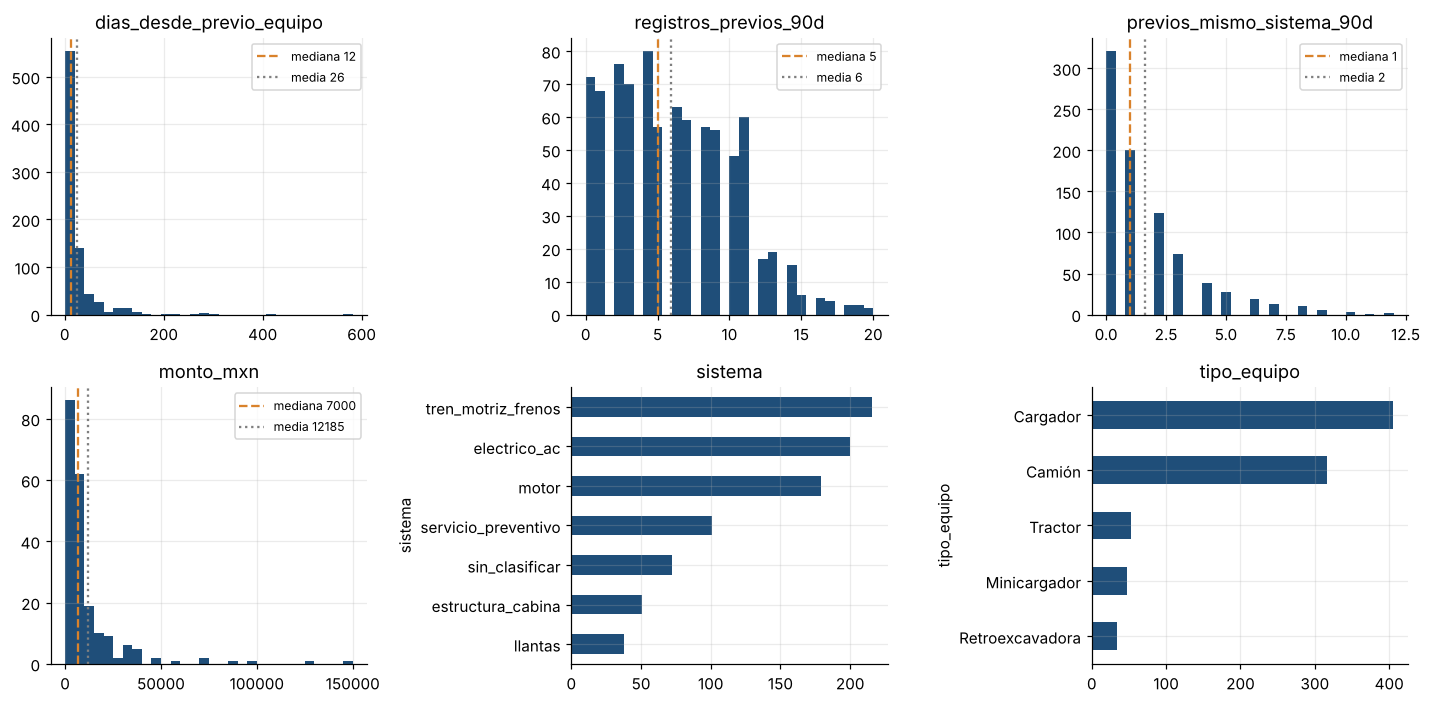

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(13, 6.5))
for a, c in zip(ax.ravel()[:4], ['dias_desde_previo_equipo','registros_previos_90d','previos_mismo_sistema_90d','monto_mxn']):
    x = df[c].dropna(); a.hist(x, bins=30, color=AZ); a.axvline(x.median(), color=NA, ls='--', label=f'mediana {x.median():.0f}')
    a.axvline(x.mean(), color=GR, ls=':', label=f'media {x.mean():.0f}'); a.set_title(c); a.legend(fontsize=8)
df.sistema.value_counts().plot.barh(ax=ax[1,1], color=AZ); ax[1,1].set_title('sistema'); ax[1,1].invert_yaxis()
df.tipo_equipo.value_counts().plot.barh(ax=ax[1,2], color=AZ); ax[1,2].set_title('tipo_equipo'); ax[1,2].invert_yaxis()
plt.tight_layout(); plt.show()

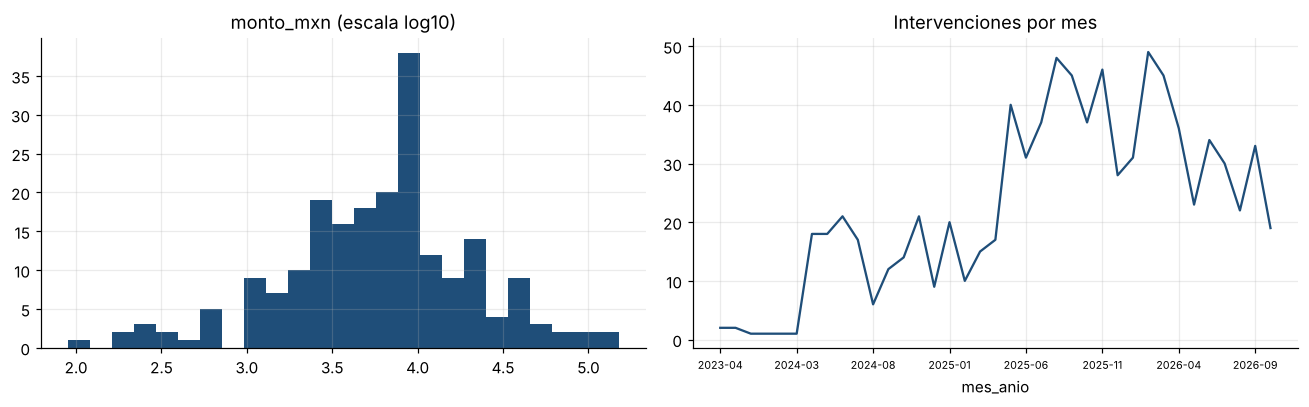

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.log10(df.monto_mxn.dropna()); ax[0].hist(x, bins=25, color=AZ); ax[0].set_title('monto_mxn (escala log10)')
m = df.dropna(subset=['fecha']).copy(); m['mes_anio'] = pd.to_datetime(m.fecha).dt.to_period('M').astype(str)
m.groupby('mes_anio').size().plot(ax=ax[1], color=AZ); ax[1].set_title('Intervenciones por mes'); ax[1].tick_params(axis='x', labelsize=7)
plt.tight_layout(); plt.show()

**Lectura.** `monto_mxn` y `dias_desde_previo_equipo` están muy sesgadas a la derecha (media mayor que mediana): hay muchas intervenciones baratas/cercanas en el tiempo y pocas muy caras/espaciadas. En escala logarítmica `monto_mxn` se parece más a una campana, por lo que conviene usarla así. Los conteos de historial previo son discretos y también sesgados.

## 5. Correlación

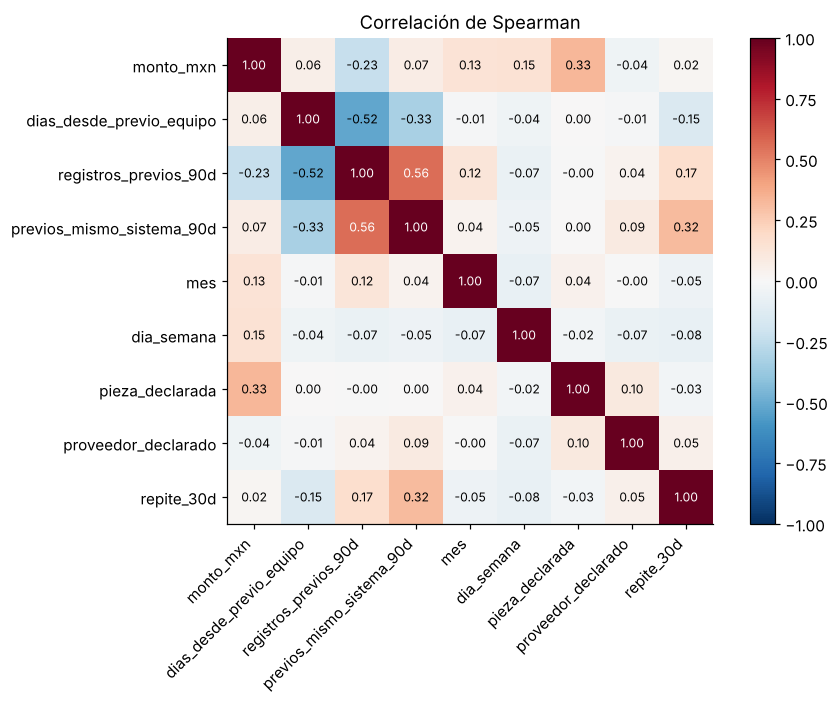

In [7]:
cols = ['monto_mxn','dias_desde_previo_equipo','registros_previos_90d','previos_mismo_sistema_90d','mes','dia_semana','pieza_declarada','proveedor_declarado','repite_30d']
cor = df[cols].astype(float).corr(method='spearman')
fig, a = plt.subplots(figsize=(8.5, 6.5))
im = a.imshow(cor, cmap='RdBu_r', vmin=-1, vmax=1)
a.set_xticks(range(len(cols))); a.set_xticklabels(cols, rotation=45, ha='right'); a.set_yticks(range(len(cols))); a.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = cor.iloc[i, j]
        if not np.isnan(v): a.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > .55 else 'black')
a.grid(False); plt.colorbar(im, fraction=.046); a.set_title('Correlación de Spearman'); plt.tight_layout(); plt.show()

In [8]:
cor['repite_30d'].drop('repite_30d').sort_values(key=abs, ascending=False).round(3)

previos_mismo_sistema_90d    0.316
registros_previos_90d        0.171
dias_desde_previo_equipo    -0.148
dia_semana                  -0.075
proveedor_declarado          0.054
mes                         -0.049
pieza_declarada             -0.026
monto_mxn                    0.017
Name: repite_30d, dtype: float64

**Lectura.** Se usa Spearman porque las variables son sesgadas. La señal más clara con el objetivo viene del historial reciente del equipo: más intervenciones previas del mismo sistema en 90 días (ρ ≈ 0.32) y menos días desde la intervención anterior (ρ ≈ −0.15). El monto y el mes casi no se relacionan con el objetivo.

## 6. Relación de las variables con el objetivo

In [9]:
lab = df[df.repite_30d.notna()].copy()
res = []
for c in ['sistema','tipo_equipo','fuente']:
    t = pd.crosstab(lab[c], lab.repite_30d); res.append((c, 'chi²', stats.chi2_contingency(t)[1]))
for c in ['dias_desde_previo_equipo','registros_previos_90d','previos_mismo_sistema_90d','monto_mxn','mes']:
    a, b = lab[lab.repite_30d == 1][c].dropna(), lab[lab.repite_30d == 0][c].dropna()
    res.append((c, 'Mann-Whitney', stats.mannwhitneyu(a, b).pvalue))
pd.DataFrame(res, columns=['variable','prueba','p-valor']).assign(significativa=lambda t: t['p-valor'] < .05).round(4)

,variable,prueba,p-valor,significativa
0,sistema,chi²,0.0000,True
1,tipo_equipo,chi²,0.2328,False
2,fuente,chi²,0.0904,False
3,dias_desde_previo_equipo,Mann-Whitney,0.0002,True
4,registros_previos_90d,Mann-Whitney,0.0000,True
5,previos_mismo_sistema_90d,Mann-Whitney,0.0000,True
6,monto_mxn,Mann-Whitney,0.8278,False
7,mes,Mann-Whitney,0.2150,False


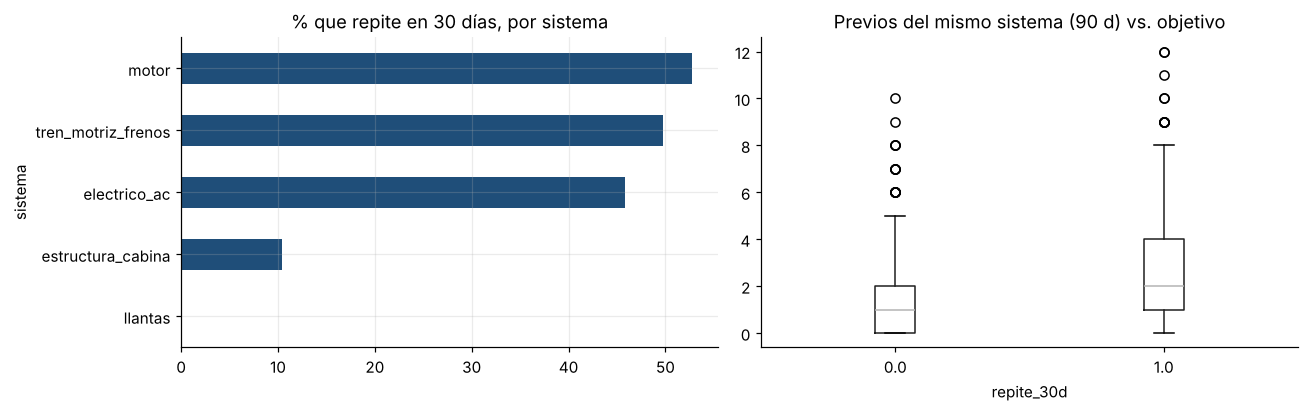

                    count   mean
sistema                         
electrico_ac          190  0.458
estructura_cabina      48  0.104
llantas                36  0.000
motor                 161  0.528
tren_motriz_frenos    209  0.498


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(lab.groupby('sistema').repite_30d.mean().sort_values()*100).plot.barh(ax=ax[0], color=AZ); ax[0].set_title('% que repite en 30 días, por sistema')
lab.boxplot(column='previos_mismo_sistema_90d', by='repite_30d', ax=ax[1], grid=False); ax[1].set_title('Previos del mismo sistema (90 d) vs. objetivo'); plt.suptitle('')
plt.tight_layout(); plt.show()
print(lab.groupby('sistema').repite_30d.agg(['count','mean']).round(3))

**Lectura.** El sistema afectado es la variable más informativa: motor, tren motriz/frenos y eléctrico repiten en ~46–53 % de los casos; estructura/cabina en ~10 % y llantas en 0 % (pocos casos, 36). El tipo de equipo y la fuente no muestran diferencia significativa. Los equipos con más historial reciente repiten más.

## 7. Valores nulos

In [11]:
nul = pd.DataFrame({'nulos': df.isna().sum(), '%': (100*df.isna().mean()).round(1)})
nul[nul.nulos > 0].sort_values('%', ascending=False)

,nulos,%
intervalo_servicio_h,793,92.5
monto_mxn,649,75.7
repite_30d,213,24.9
dias_desde_previo_equipo,42,4.9
fecha,17,2.0
dia_semana,17,2.0
mes,17,2.0
registros_previos_90d,17,2.0
previos_mismo_sistema_90d,17,2.0


| Variable | Nulos | Causa | Tratamiento propuesto |
|---|---|---|---|
| `monto_mxn` | ~76 % | La empresa no anota costo en la mayoría de las intervenciones | No imputar con un valor inventado. Crear indicador `monto_declarado` (sí/no) y usar el monto solo en el subconjunto que lo tiene; en modelos, imputación por mediana *por sistema* dentro del entrenamiento. |
| `intervalo_servicio_h` | ~93 % | Solo aplica a servicios preventivos | Excluir de las variables del modelo; los servicios no tienen objetivo. |
| `fecha` y derivadas (`mes`, `dia_semana`, historial) | ~2 % | Anotaciones con solo el año | Dejar vacías; esas filas se excluyen del entrenamiento (no se inventa fecha). |
| `dias_desde_previo_equipo` | ~5 % | Primera intervención de cada equipo | Imputar con un valor grande (p. ej. 365) más indicador de “sin previo”. |
| `repite_30d` | ~25 % | Servicios, sin clasificar, sin fecha y últimos 30 días (censura) | Se excluyen del entrenamiento y la evaluación; no son negativos. |

## 8. Valores atípicos

In [12]:
def iqr(x):
    x = x.dropna(); q1, q3 = x.quantile([.25, .75]); i = q3 - q1; lo, hi = q1 - 1.5*i, q3 + 1.5*i
    return pd.Series({'n': len(x), 'atípicos': int(((x < lo) | (x > hi)).sum()), 'límite_sup': hi, 'máximo': x.max(), 'P99': x.quantile(.99)})
pd.DataFrame({c: iqr(df[c]) for c in ['monto_mxn','dias_desde_previo_equipo','registros_previos_90d','previos_mismo_sistema_90d']}).T.round(1)

,n,atípicos,límite_sup,máximo,P99
monto_mxn,208.0,22.0,25961.2,150000.0,99300.0
dias_desde_previo_equipo,815.0,77.0,60.0,582.0,254.7
registros_previos_90d,840.0,2.0,19.5,20.0,17.0
previos_mismo_sistema_90d,840.0,55.0,5.0,12.0,9.0


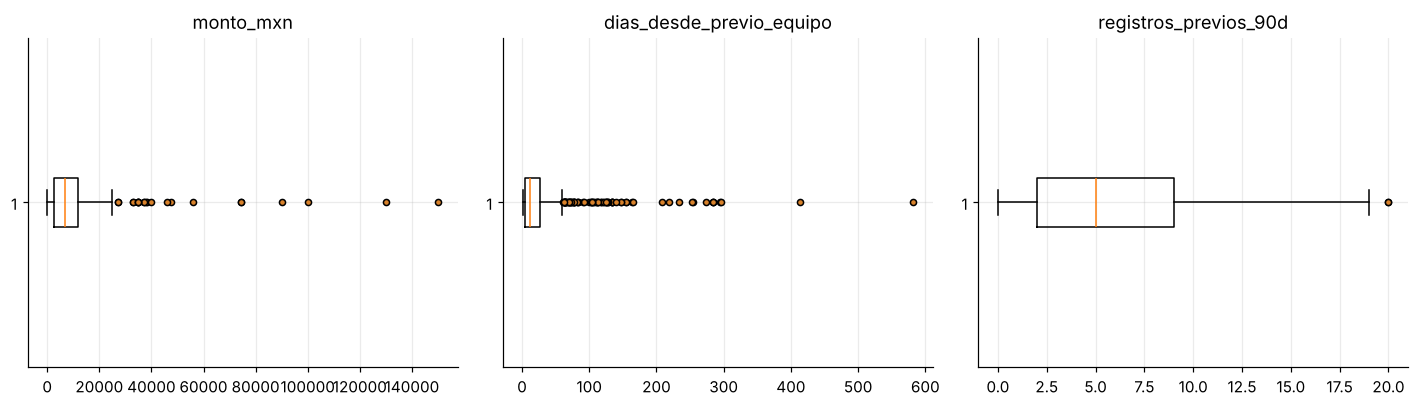

,fuente,equipo_id,fecha,sistema,monto_mxn
406,libreta_taller,K4,2025-11-20,electrico_ac,150000.0
808,libreta_taller,T1,2025-01-03,electrico_ac,130000.0
404,libreta_taller,K4,2025-11-07,electrico_ac,100000.0
408,libreta_taller,K4,2026-02-22,electrico_ac,90000.0
269,bitacora_camiones,C7,2025-03-25,estructura_cabina,74500.0


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, c in zip(ax, ['monto_mxn','dias_desde_previo_equipo','registros_previos_90d']):
    a.boxplot(df[c].dropna(), vert=False, flierprops=dict(marker='o', markerfacecolor=NA, markersize=4)); a.set_title(c)
plt.tight_layout(); plt.show()
df.nlargest(5, 'monto_mxn')[['fuente','equipo_id','fecha','sistema','monto_mxn']]

| Variable | Hallazgo | Tratamiento propuesto |
|---|---|---|
| `monto_mxn` | 22 atípicos por regla IQR (> ≈ $26,000); el máximo (~$150,000) es de motor | No eliminar: son reparaciones mayores reales. Usar `log(1+monto)` y/o recortar en el percentil 99 solo para modelos sensibles a escala; reportar mediana. |
| `dias_desde_previo_equipo` | 77 por encima de ≈ 60 días | Son equipos con pocas fallas, no errores. Transformar con log y mantener. |
| Conteos de historial | Colas largas en equipos muy intensivos | Mantener; usar modelos basados en árboles o escalado robusto. |

Ningún valor atípico parece error de captura; se conservan y se tratan con transformaciones.

## 9. Conclusiones y siguientes pasos
- Hay **857** intervenciones reales (≥ 500) y más de 5 variables explicativas numéricas y categóricas; **644** tienen etiqueta para clasificación.
- El objetivo `repite_30d` está razonablemente balanceado (~44 % positivos), lo que facilita el modelado.
- Las variables más útiles son el **sistema** y el **historial reciente** del equipo; monto y mes aportan poco.
- Limitaciones: la libreta no está validada por la empresa, el monto falta en ~76 % y el periodo cubre ~3.5 años con equipos de distinta intensidad de uso.
- Siguiente paso: entrenar y comparar clasificadores (regresión logística, árbol, bosque aleatorio) con validación temporal y reportar matriz de confusión, precisión, recall y F1.